Saving waterQuality1.csv to waterQuality1 (11).csv
Dropped 3 rows because target column had missing values.
Dataframe shape after cleaning: (7996, 21)
Target encoded with classes: ['0', '1']
X shape: (7996, 20) | y shape: (7996,)
Train: (5357, 20) | Test: (2639, 20)

Accuracy (All features): 89.81%

================ ANOVA RESULTS ================
Best K (ANOVA): 11
Best Accuracy (ANOVA): 89.84%
Selected ANOVA feature indices: [0, 2, 3, 4, 5, 6, 10, 12, 15, 16, 18]
ANOVA removed 9 features


================ MI RESULTS ================
Best K (MI): 11
Best Accuracy (MI): 89.96%
Selected MI feature indices: [0, 2, 3, 4, 5, 6, 13, 14, 15, 16, 18]
MI removed 9 features


================ SUMMARY ================
Accuracy (All Features): 89.81%
ANOVA Best K = 11 → Accuracy = 89.84%
MI Best K = 11 → Accuracy = 89.96%


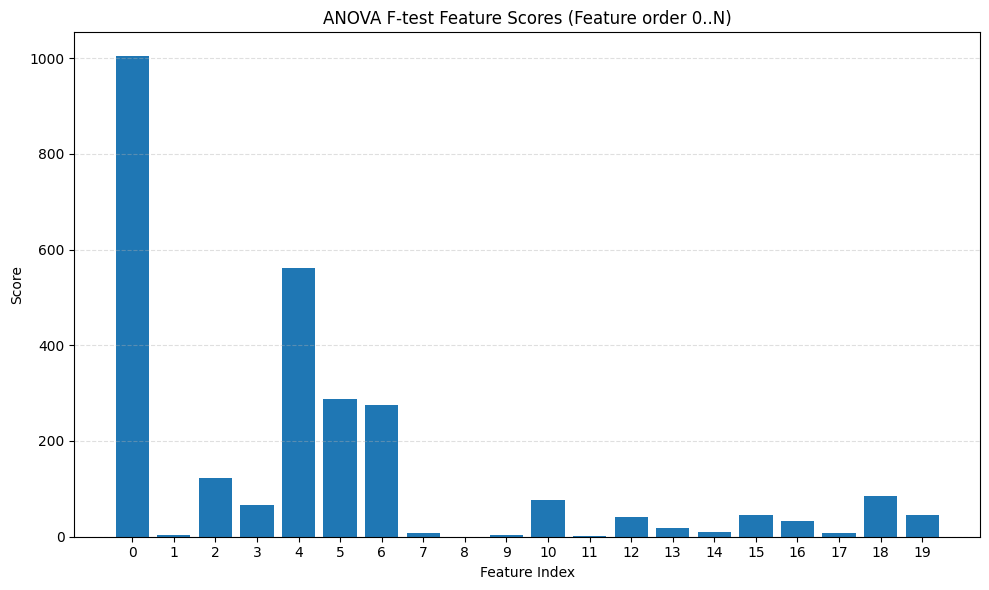

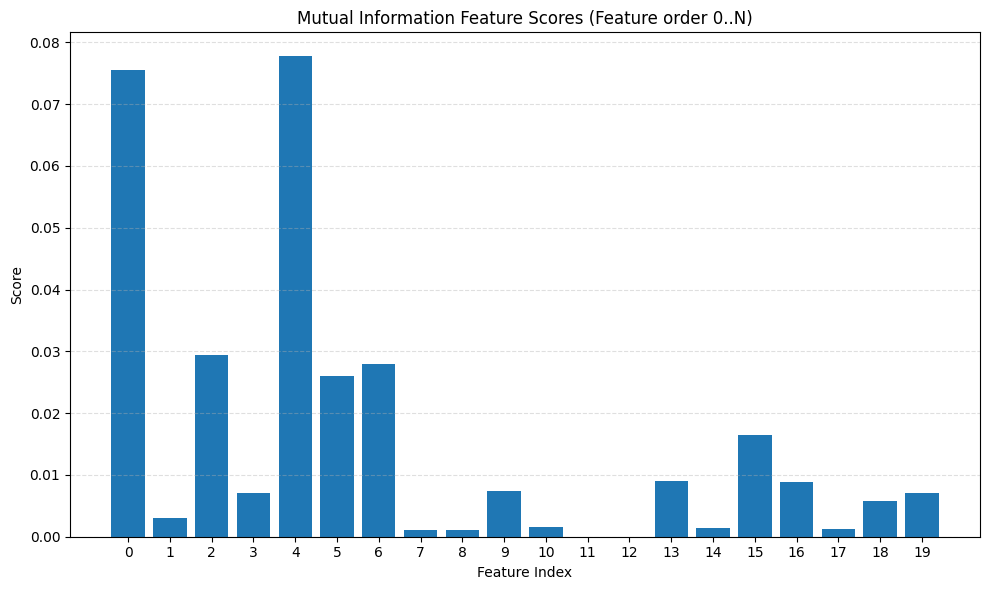

In [13]:
# -------------------------
# Robust ANOVA vs MI Feature Selection
# -------------------------
from google.colab import files
uploaded = files.upload()

import numpy as np
import pandas as pd
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# -------------------------
# Load + clean dataframe
# -------------------------
def load_and_clean_df(filename):
    df = read_csv(filename)

    # Replace common missing value indicators with np.nan
    df = df.replace(['#NUM!', '#DIV/0!', '#REF!', '#VALUE!', '#NULL!', '#N/A', ''], np.nan)

    target_col = df.columns[-1]
    before = df.shape[0]
    df = df.dropna(subset=[target_col])
    after = df.shape[0]

    if before != after:
        print(f"Dropped {before - after} rows because target column had missing values.")

    return df

# -------------------------
# Preprocess X and y
# -------------------------
def preprocess_df(df):
    X_df = df.iloc[:, :-1].copy()
    y_ser = df.iloc[:, -1].copy()

    # Encode target if object type
    if y_ser.dtype == object:
        y_ser = y_ser.astype(str)
        le_y = LabelEncoder()
        y = le_y.fit_transform(y_ser)
        print(f"Target encoded with classes: {list(le_y.classes_)}")
    else:
        y = pd.to_numeric(y_ser, errors='coerce').values
        if np.isnan(y).any():
            mask = ~np.isnan(y)
            X_df = X_df.loc[mask].reset_index(drop=True)
            y = y[mask]
            print("Dropped rows with NaN in target.")

    # Process features: numeric conversion or label encoding
    for col in X_df.columns:
        if X_df[col].dtype == object:
            conv = pd.to_numeric(X_df[col], errors='coerce')
            if conv.notna().sum() > 0 and conv.isna().sum() < len(conv):
                X_df[col] = conv
            else:
                X_df[col] = LabelEncoder().fit_transform(X_df[col].astype(str))

    # Convert to float and impute missing values
    X_arr = X_df.astype(float).values
    imputer = SimpleImputer(strategy="mean")
    X_imp = imputer.fit_transform(X_arr)

    return X_imp, np.asarray(y)

# -------------------------
# Plot feature scores in original feature order
# -------------------------
def plot_feature_scores(scores, title):
    plt.figure(figsize=(10,6))
    plt.bar(range(len(scores)), scores)
    plt.title(title)
    plt.xlabel("Feature Index")
    plt.ylabel("Score")
    plt.xticks(range(len(scores)))
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

# -------------------------
# Evaluate best K for feature selection
# -------------------------
def find_best_k(method, X_train, y_train, X_test, y_test):
    max_k = X_train.shape[1]
    acc_list = []
    for k in range(1, max_k+1):
        fs = SelectKBest(method, k=k)
        Xtr = fs.fit_transform(X_train, y_train)
        Xte = fs.transform(X_test)

        model = LogisticRegression(solver='liblinear', max_iter=1000)
        model.fit(Xtr, y_train)

        acc = accuracy_score(y_test, model.predict(Xte))
        acc_list.append(acc)

    best_k = np.argmax(acc_list) + 1
    best_acc = acc_list[best_k-1]

    return best_k, best_acc, acc_list

# -------------------------
# MAIN
# -------------------------
df = load_and_clean_df("waterQuality1.csv")
print("Dataframe shape after cleaning:", df.shape)

X, y = preprocess_df(df)
print("X shape:", X.shape, "| y shape:", y.shape)

if np.isnan(X).any(): raise ValueError("X contains NaN after preprocessing.")
if np.isnan(y).any(): raise ValueError("y contains NaN after preprocessing.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# -------------------------
# Accuracy using ALL features
# -------------------------
clf_all = LogisticRegression(solver='liblinear', max_iter=1000)
clf_all.fit(X_train, y_train)
acc_all = accuracy_score(y_test, clf_all.predict(X_test))
print(f"\nAccuracy (All features): {acc_all*100:.2f}%")

# -------------------------
# FIND BEST K — ANOVA
# -------------------------
anova_best_k, anova_best_acc, _ = find_best_k(f_classif, X_train, y_train, X_test, y_test)
fs_anova_best = SelectKBest(f_classif, k=anova_best_k)
fs_anova_best.fit(X_train, y_train)
anova_indices = fs_anova_best.get_support(indices=True)

print("\n================ ANOVA RESULTS ================")
print(f"Best K (ANOVA): {anova_best_k}")
print(f"Best Accuracy (ANOVA): {anova_best_acc*100:.2f}%")
print(f"Selected ANOVA feature indices: {anova_indices.tolist()}")
print(f"ANOVA removed {X.shape[1] - anova_best_k} features\n")

# -------------------------
# FIND BEST K — Mutual Information
# -------------------------
mi_best_k, mi_best_acc, _ = find_best_k(mutual_info_classif, X_train, y_train, X_test, y_test)
fs_mi_best = SelectKBest(mutual_info_classif, k=mi_best_k)
fs_mi_best.fit(X_train, y_train)
mi_indices = fs_mi_best.get_support(indices=True)

print("\n================ MI RESULTS ================")
print(f"Best K (MI): {mi_best_k}")
print(f"Best Accuracy (MI): {mi_best_acc*100:.2f}%")
print(f"Selected MI feature indices: {mi_indices.tolist()}")
print(f"MI removed {X.shape[1] - mi_best_k} features\n")

# -------------------------
# SUMMARY
# -------------------------
print("\n================ SUMMARY ================")
print(f"Accuracy (All Features): {acc_all*100:.2f}%")
print(f"ANOVA Best K = {anova_best_k} → Accuracy = {anova_best_acc*100:.2f}%")
print(f"MI Best K = {mi_best_k} → Accuracy = {mi_best_acc*100:.2f}%")

# -------------------------
# Feature scores plots in original feature order
# -------------------------
f_scores, _ = f_classif(X, y)
plot_feature_scores(f_scores, "ANOVA F-test Feature Scores (Feature order 0..N)")

mi_scores = mutual_info_classif(X, y, random_state=42)
plot_feature_scores(mi_scores, "Mutual Information Feature Scores (Feature order 0..N)")
